# PinFuse minimal demo — Xenium mouse brain

This notebook is the shortest path through PinFuse: download a Xenium dataset, train
`PinFuse_Cell`, predict, and look at the denoised output.

| step | what happens |
|---|---|
| 0 | environment check (torch / dgl / CUDA) |
| 1 | download `xenium_tutorial.h5ad` from the scanpy figshare |
| 2 | config: `config/xenium_configs.py`, the recipe for this dataset |
| 3 | prepare: `dataio.from_anndata` crops to the left hemisphere |
| 4 | define: `train.build_model` turns the config into a `PinFuse_Cell` |
| 5 | train: one call, `train.fit` |
| 6 | predict: one call, `predict.predict_all` |
| 7 | visualize: denoised genes, UMAP + Leiden, spatial clusters, gene–gene scatter |
| 8 | reload the saved run |

The whole notebook runs on one GPU. On an A800 the left hemisphere (66k cells,
248 genes, 80 neighbours) trains in about 4 minutes (4 epochs) and predicts in
about 1 minute.

## 0. Environment

PinFuse needs `torch` and `dgl`; the rest is scanpy for reading and plotting.

In [1]:
import os
import sys
import time

import numpy as np
import torch

# This notebook lives in tutorial/; the repository root is its parent. Everything is
# addressed relative to that root -- `data/` and `results/` are symlinks into the
# shared filesystem, so no absolute path appears anywhere in this notebook.
REPO = os.path.abspath(os.path.join(os.getcwd(), ".."))
if not os.path.isfile(os.path.join(REPO, "train.py")):
    raise RuntimeError(f"{REPO} is not the PinFuse root; run this notebook from tutorial/")
os.chdir(REPO)
if REPO not in sys.path:
    sys.path.insert(0, REPO)

print("repo:", os.path.basename(REPO))
print("python:", sys.version.split()[0])
print("torch:", torch.__version__, "| cuda available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("gpu:", torch.cuda.get_device_name(0))

import dgl
print("dgl:", dgl.__version__)

repo: PinFuse_Core-tutorial-202611031521
python: 3.12.13
torch: 2.6.0+cu124 | cuda available: True
gpu: NVIDIA A800-SXM4-80GB
Setting the default backend to "pytorch". You can change it in the ~/.dgl/config.json file or export the DGLBACKEND environment variable.  Valid options are: pytorch, mxnet, tensorflow (all lowercase)
dgl: 2.5.0+cu124


## 1. Download

`xenium_tutorial.h5ad` is the 10x Xenium mouse-brain dataset (130k cells, 248 genes)
used in the scanpy tutorials. `sc.read` downloads it once into `data/` and reuses the
local copy afterwards.

In [2]:
import scanpy as sc

adata_path = os.path.join("data", "xenium_tutorial.h5ad")
adata = sc.read(adata_path, backup_url="https://figshare.com/ndownloader/files/49710699")
print(adata)

AnnData object with n_obs × n_vars = 130604 × 248
    obs: 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'fov', 'predicted_celltype'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'log1p'
    obsm: 'X_resolvi_transferred', 'X_spatial', 'X_umap_transferred'
    layers: 'counts', None (.X)


## 2. Config

`config/xenium_configs.py` holds the recipe for this dataset: raw counts from the
`counts` layer, coordinates from `obsm['X_spatial']`, a crop box that keeps the left
hemisphere (x < 5000), 80 spatial neighbours per cell, and the loss weights.

In [3]:
from config.xenium_configs import get_config

config = get_config()

# Optional overrides for a quicker run:
# config.training.epochs = 2
# config.data.crop_box = (2000.0, 3000.0, 2000.0, 3000.0)   # ~3k cells

print("counts layer :", config.data.counts_layer)
print("spatial key  :", config.data.spatial_key)
print("crop box     :", config.data.crop_box)
print("neighbours   :", config.data.n_neighbors)
print("epochs       :", config.training.epochs)
print("loss weights :", {f"lam{i}": config.model[f"lam{i}"] for i in range(1, 6)})
print("device       :", config.device)

counts layer : counts
spatial key  : X_spatial
crop box     : (129.0, 5000.0, 328.0, 7033.0)
neighbours   : 80
epochs       : 4
loss weights : {'lam1': 0.0, 'lam2': 0.0, 'lam3': 0.0, 'lam4': 0.0, 'lam5': 0.05}
device       : cuda:0


The training loss is the ZINB negative log-likelihood of the observed counts plus
optional terms weighted by `lam1`..`lam5` (out-of-tissue rate, latent KL, transport
distance, transport entropy, transported share). Only `lam5` is on in this config.

## 3. Prepare

`dataio.from_anndata` applies the config's preprocessing to a copy of `adata`: it
switches `X` to raw counts and crops to the left hemisphere.

In [4]:
from dataio import from_anndata

data = from_anndata(config, adata, name="xenium_tutorial")
print(data.adata)

AnnData object with n_obs × n_vars = 66457 × 248
    obs: 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'fov', 'predicted_celltype'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'log1p'
    obsm: 'X_resolvi_transferred', 'X_spatial', 'X_umap_transferred', 'spatial'
    layers: 'counts', None (.X)


## 4. Define the model

`train.build_model` turns the `model.*` section of the config into a `PinFuse_Cell`.

In [5]:
import train

n_obs, n_gene = data.shape
model = train.build_model(config, n_gene=n_gene, n_obs=n_obs)
print(type(model).__name__, model.VERSION)
print(f"{sum(p.numel() for p in model.parameters()):,} parameters")

PinFuse_Cell v6.1
2,677,849 parameters


## 5. Train

One call. `train.fit` trains for `training.epochs` epochs and returns the trained
model. If the loss becomes NaN it restarts from a fresh initialisation with a new
seed. With `dst_dir` it also saves the config and `checkpoints/checkpoint.pth`.

In [6]:
DST_DIR = os.path.join("results", "xenium_tutorial")

t0 = time.time()
model = train.fit(config, data, model=model, dst_dir=DST_DIR)
print(f"trained in {time.time() - t0:.0f}s")

1 / 4 | 2077 / 2077 : 7.408e-01 : 0.000e+00 : 3.005e+02 : 1.176e-02 : -5.106e-02 : 3.166e-01     
2 / 4 | 2077 / 2077 : 7.214e-01 : 0.000e+00 : 2.713e+02 : 1.173e-02 : -5.081e-02 : 3.136e-01     
3 / 4 | 2077 / 2077 : 7.089e-01 : 0.000e+00 : 2.578e+02 : 1.170e-02 : -5.078e-02 : 3.278e-01     
4 / 4 | 2077 / 2077 : 6.650e-01 : 0.000e+00 : 2.609e+02 : 1.151e-02 : -5.053e-02 : 3.285e-01     
trained in 235s


## 6. Predict

One call. `predict.predict_all` runs every inference pass and writes the results into
`data.adata` in place.

In [7]:
from predict import predict_all

t0 = time.time()
adata_den = predict_all(config, data.adata, model)
print(f"predicted in {time.time() - t0:.0f}s")

# Save the denoised AnnData and metadata under DST_DIR so the reload cell below works.
from dataio import subdir, ARTIFACT_DIR
from train import set_output_metadata
set_output_metadata(adata_den, config, model)
data.adata = adata_den
data.save(subdir(DST_DIR, ARTIFACT_DIR))
print("saved to", DST_DIR)
print(adata_den)

2077 / 2077    
2077 / 2077    
2077 / 2077    
predicted in 72s
saved to results/xenium_tutorial
AnnData object with n_obs × n_vars = 66457 × 248
    obs: 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'fov', 'predicted_celltype', 'n_counts', 'n_counts_generated', 'n_counts_generated_constr', 'n_counts_sampled', 'log_diffusivity'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'log1p', 'ver', 'lam1', 'lam2', 'n_nei', 'locality', 'meta'
    obsm: 'X_resolvi_transferred', 'X_spatial', 'X_umap_transferred', 'spatial', 'index_neighbor', 'in_tissue', 'latent', 'predictions', 'reconstruct', 'predictions_count', 'reconstruct_count', 'dropout', 'dispersion', 'direction', 'direction_tol'
    layers: 'counts', None (.X)


### Outputs

`predict_all` writes the following fields into `adata_den`:

| field | content |
|---|---|
| `obsm['latent']` | 10-d latent per cell |
| `obsm['predictions']` | denoised expression rate |
| `obsm['reconstruct']` | rate after transport |
| `obsm['predictions_count']` | sampled counts from the rate |
| `obsm['dropout']`, `obsm['dispersion']` | ZINB parameters |
| `obs['n_counts']` / `obs['n_counts_generated']` | observed vs denoised library size |
| `obsm['direction_tol']` | per-cell net flow vector |

In [8]:
for key in ["latent", "predictions", "reconstruct", "predictions_count", "dropout", "dispersion"]:
    print(f"{key:20s} {adata_den.obsm[key].shape}")

print()
print("total counts  observed :", f"{adata_den.obs['n_counts'].sum():.3e}")
print("total counts  denoised :", f"{adata_den.obs['n_counts_generated'].sum():.3e}")

latent               (66457, 10)
predictions          (66457, 248)
reconstruct          (66457, 248)
predictions_count    (66457, 248)
dropout              (66457, 1)
dispersion           (66457, 1)

total counts  observed : 1.649e+07
total counts  denoised : 1.652e+07


## 7. Visualize

### 7a. Denoised genes

Two marker genes with different spatial patterns:

* `Prox1` — brightest in the dentate gyrus granule layer (the band in the
  hippocampus), and also expressed across the thalamus,
* `Slc17a6` — glutamatergic marker, highest in the thalamus.

Raw counts are shown next to the denoised rate on the same colour scale.

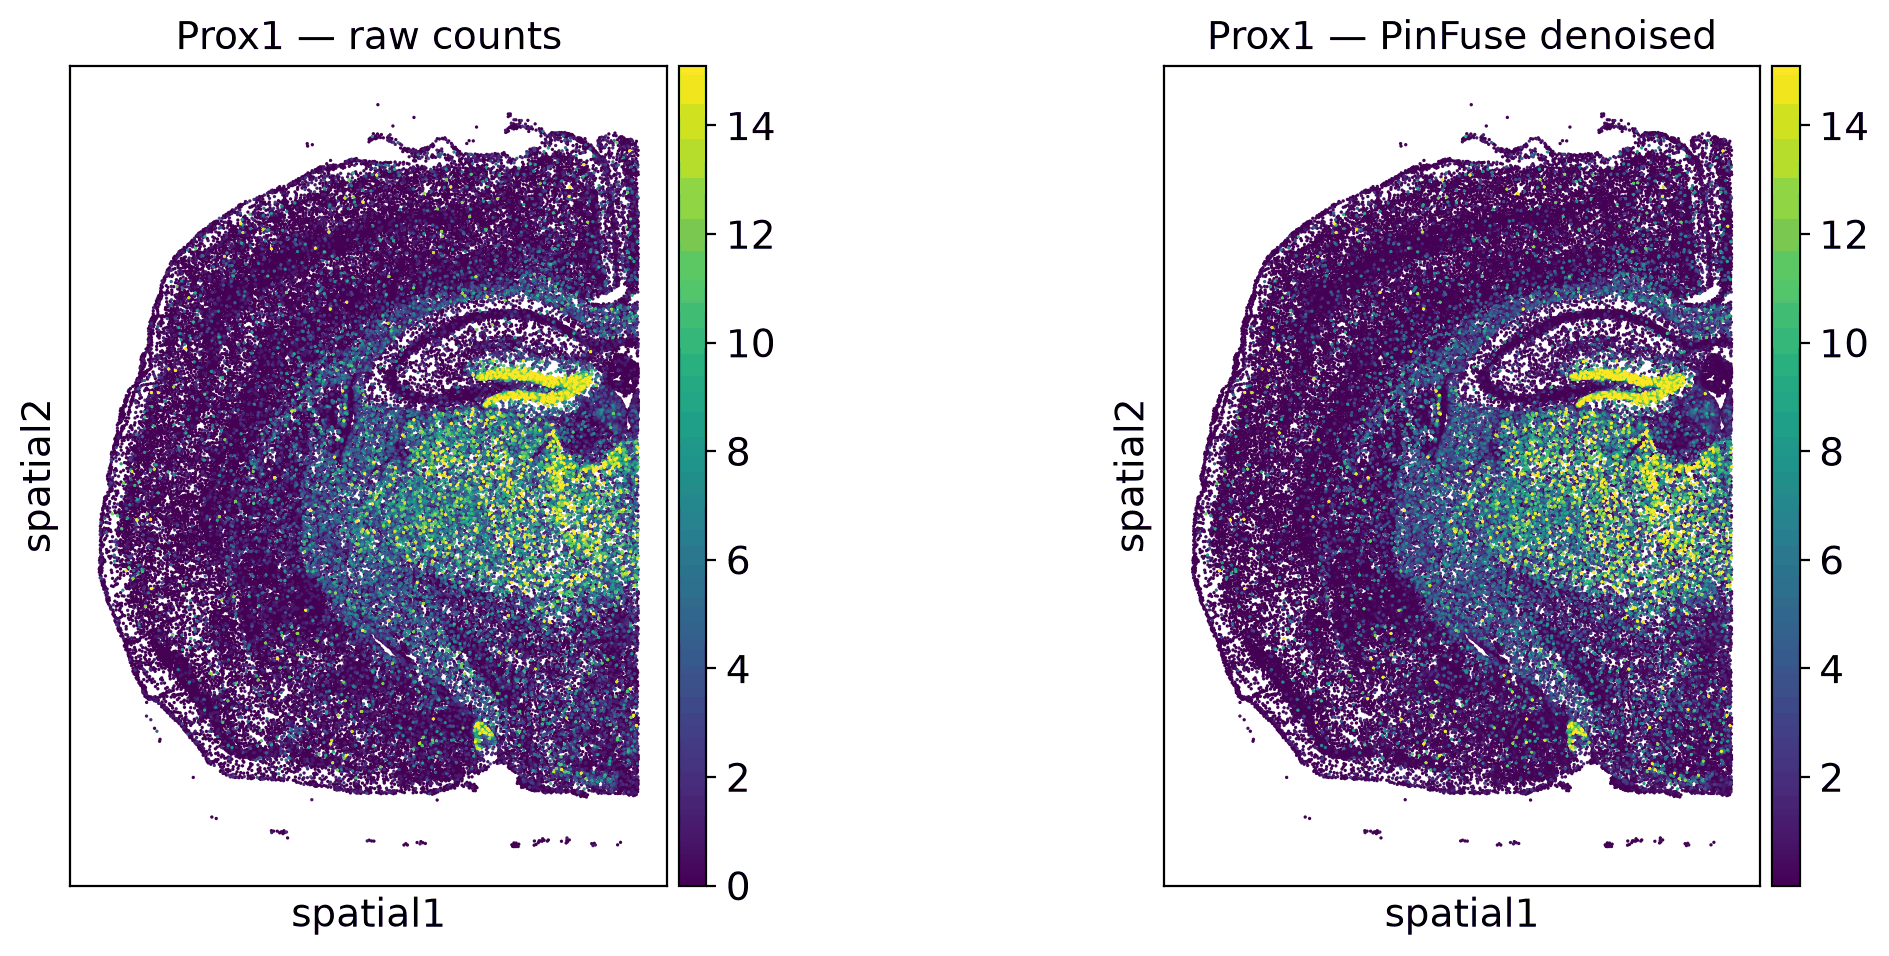

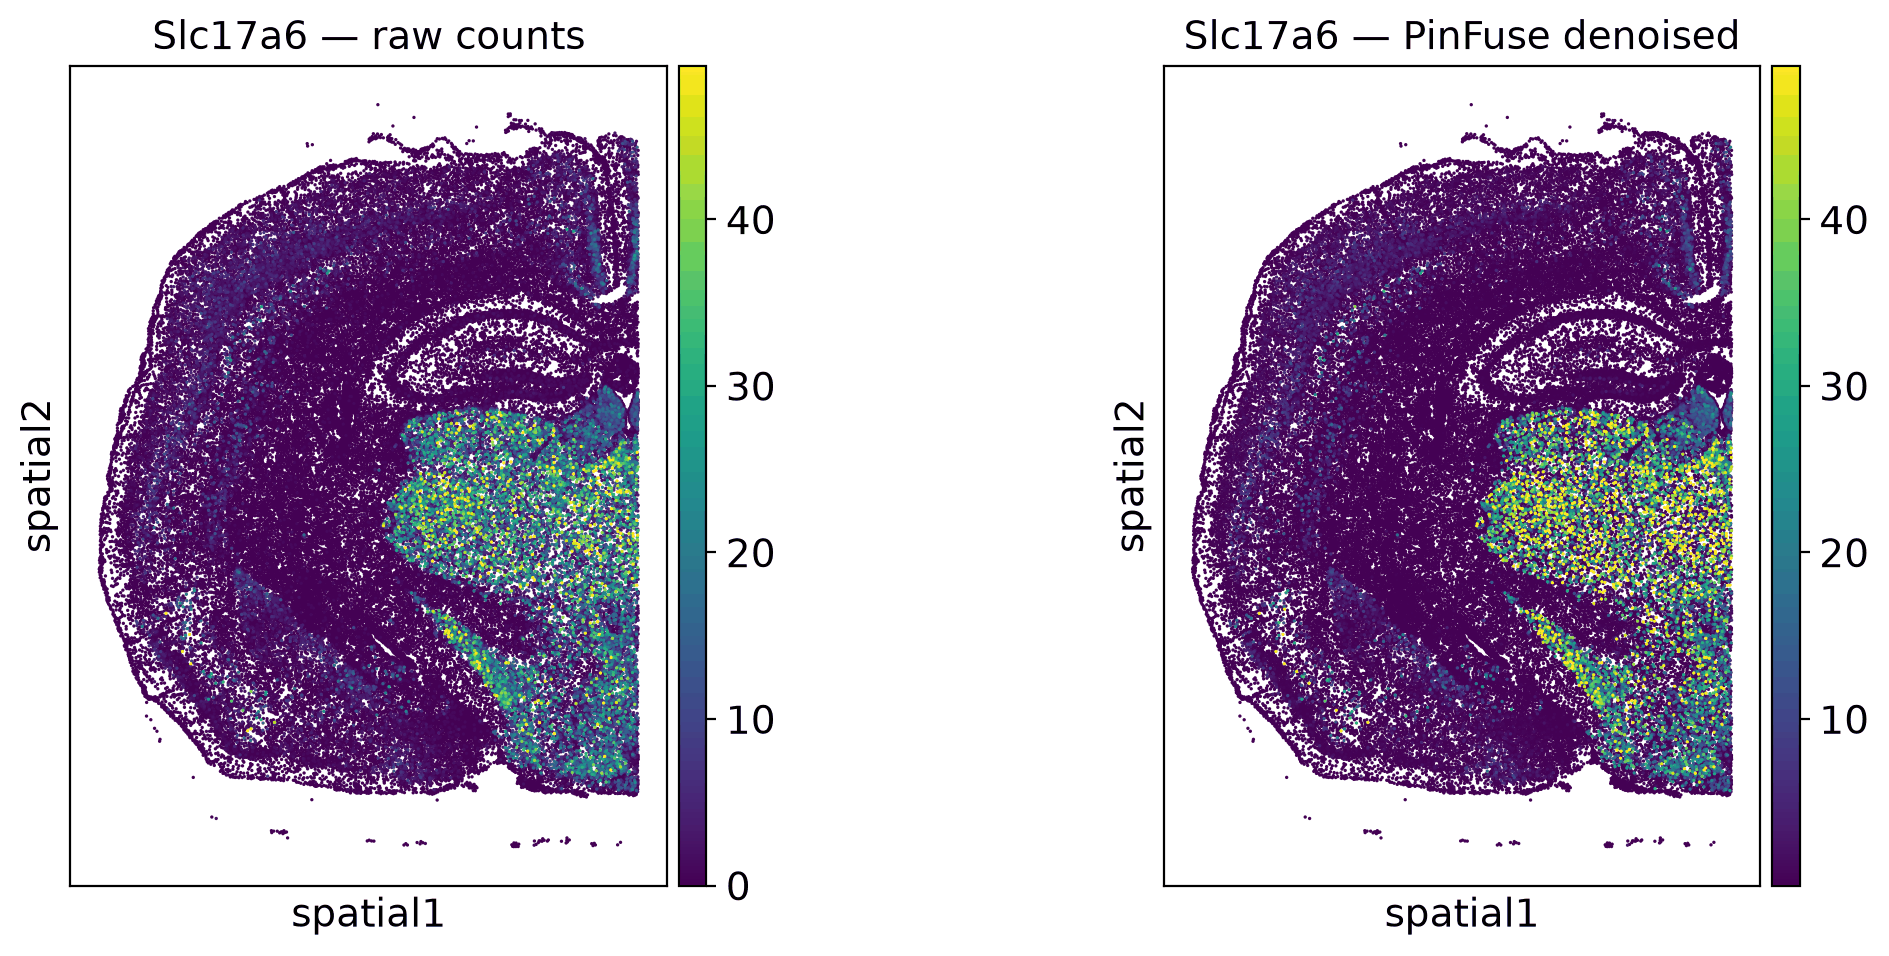

In [9]:
import matplotlib.pyplot as plt

sc.set_figure_params(figsize=(6, 6), dpi=100)


def gene_obs(gene, denoised):
    # Per-cell vector of one gene, observed (raw counts) or denoised (PinFuse rate).
    idx = adata_den.var_names.get_loc(gene)
    if denoised:
        return adata_den.obsm["predictions"][:, idx]
    x = adata_den.layers["counts"][:, idx]
    return np.asarray(x.todense()).ravel() if hasattr(x, "todense") else np.asarray(x).ravel()


def plot_gene(gene, spot_size=30):
    raw, den = gene_obs(gene, False), gene_obs(gene, True)
    vmax = np.percentile(den, 99)
    adata_den.obs[f"{gene}_raw"] = raw
    adata_den.obs[f"{gene}_denoised"] = den
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    sc.pl.spatial(adata_den, color=f"{gene}_raw",      spot_size=spot_size, vmax=vmax, ax=axes[0], show=False)
    sc.pl.spatial(adata_den, color=f"{gene}_denoised", spot_size=spot_size, vmax=vmax, ax=axes[1], show=False)
    axes[0].set_title(f"{gene} — raw counts")
    axes[1].set_title(f"{gene} — PinFuse denoised")
    plt.tight_layout()
    return fig


for gene in ["Prox1", "Slc17a6"]:
    plot_gene(gene)
    plt.show()

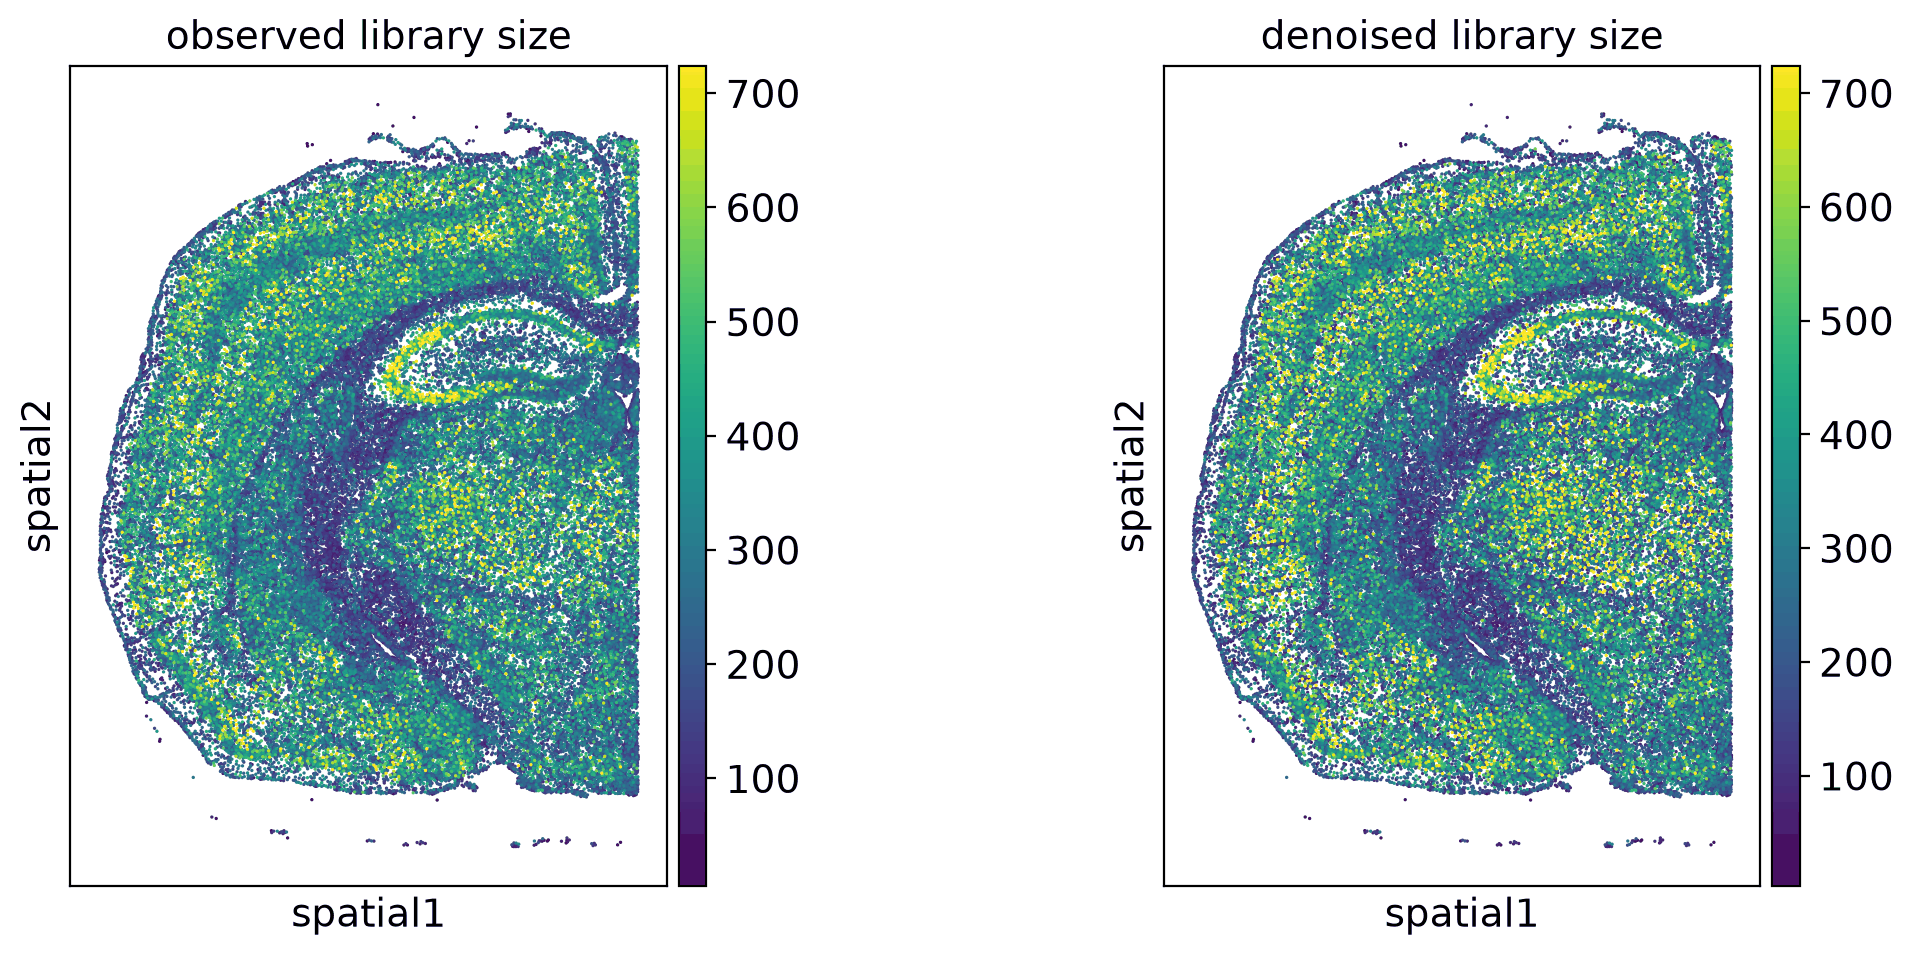

In [10]:
# Library size before and after: denoising redistributes counts, it does not invent them.
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
vmax = np.percentile(adata_den.obs["n_counts"], 99)
sc.pl.spatial(adata_den, color="n_counts",          spot_size=30, vmax=vmax, ax=axes[0], show=False)
sc.pl.spatial(adata_den, color="n_counts_generated", spot_size=30, vmax=vmax, ax=axes[1], show=False)
axes[0].set_title("observed library size")
axes[1].set_title("denoised library size")
plt.tight_layout()
plt.show()

### 7b. UMAP and Leiden

Neighbours are computed on the latent representation, not on PCA, then UMAP for the
plot and Leiden for the clusters. The adjusted Rand index against the dataset's own
`predicted_celltype` labels is a sanity check — the model never saw those labels.

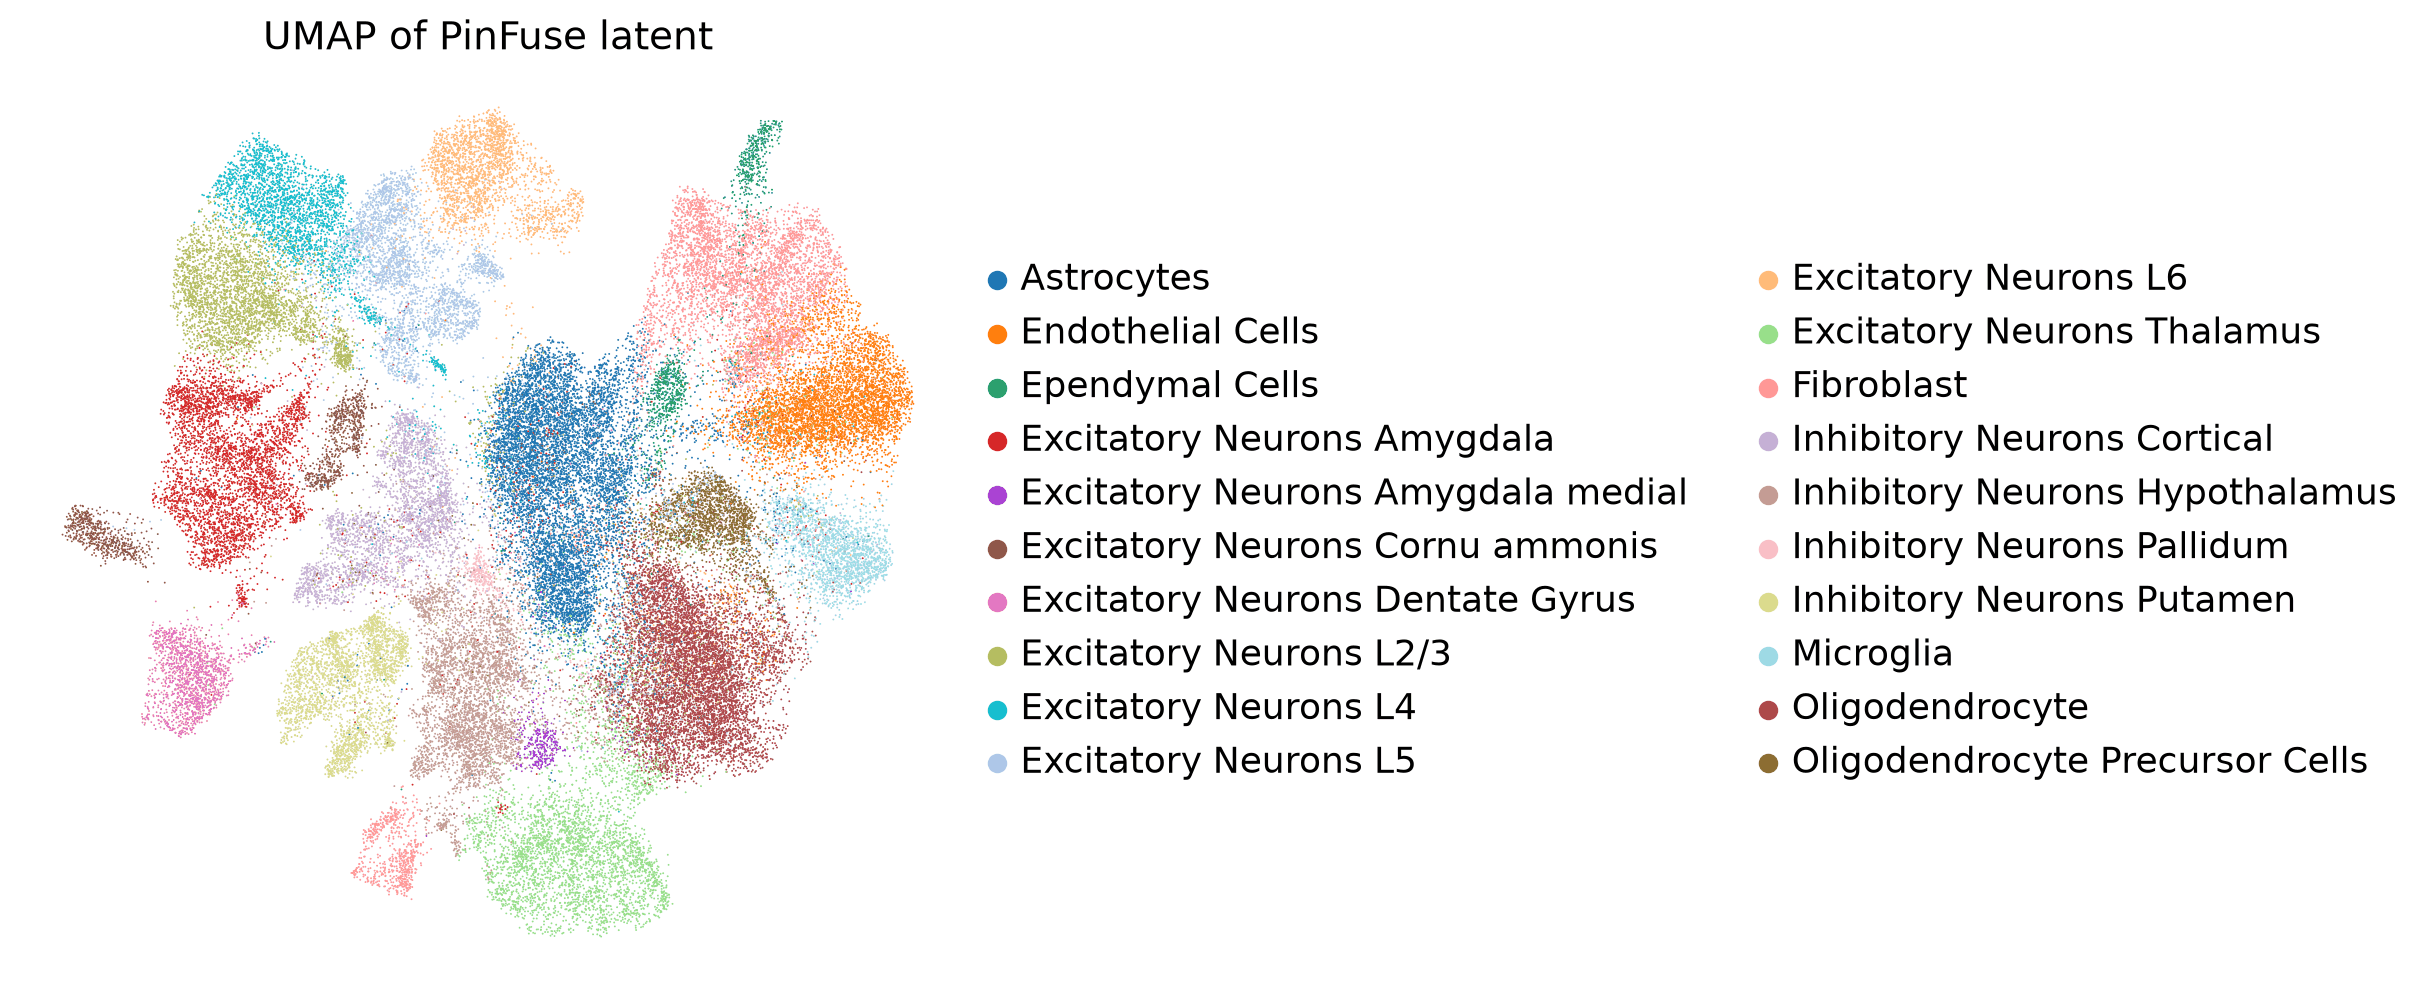

In [12]:
sc.pp.neighbors(adata_den, use_rep="latent")
sc.tl.umap(adata_den)
sc.pl.umap(adata_den, color=["predicted_celltype"], frameon=False, title="UMAP of PinFuse latent")
plt.show()

ARI vs predicted_celltype: 0.6612
clusters: 30


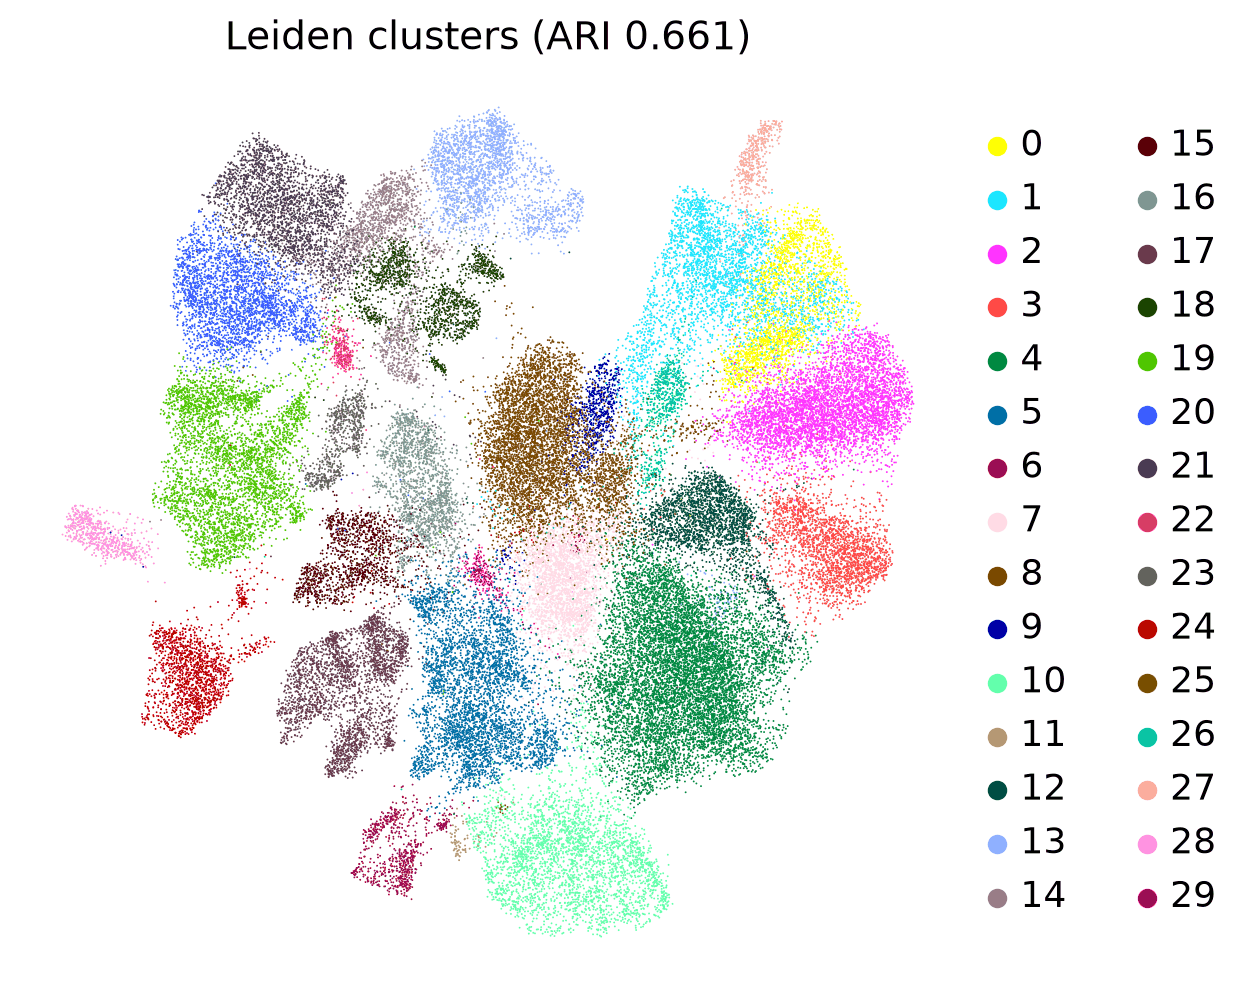

In [13]:
sc.tl.leiden(adata_den, key_added="leiden", flavor="igraph", n_iterations=2, directed=False)

from sklearn.metrics import adjusted_rand_score
ari = adjusted_rand_score(adata_den.obs["predicted_celltype"], adata_den.obs["leiden"])
print(f"ARI vs predicted_celltype: {ari:.4f}")
print("clusters:", adata_den.obs["leiden"].nunique())

sc.pl.umap(adata_den, color="leiden", frameon=False, title=f"Leiden clusters (ARI {ari:.3f})")
plt.show()

### 7c. Clusters in space

Clusters found on the latent alone, mapped back onto the tissue. Coordinates enter only through each cell's spatial neighbourhood in the encoder.

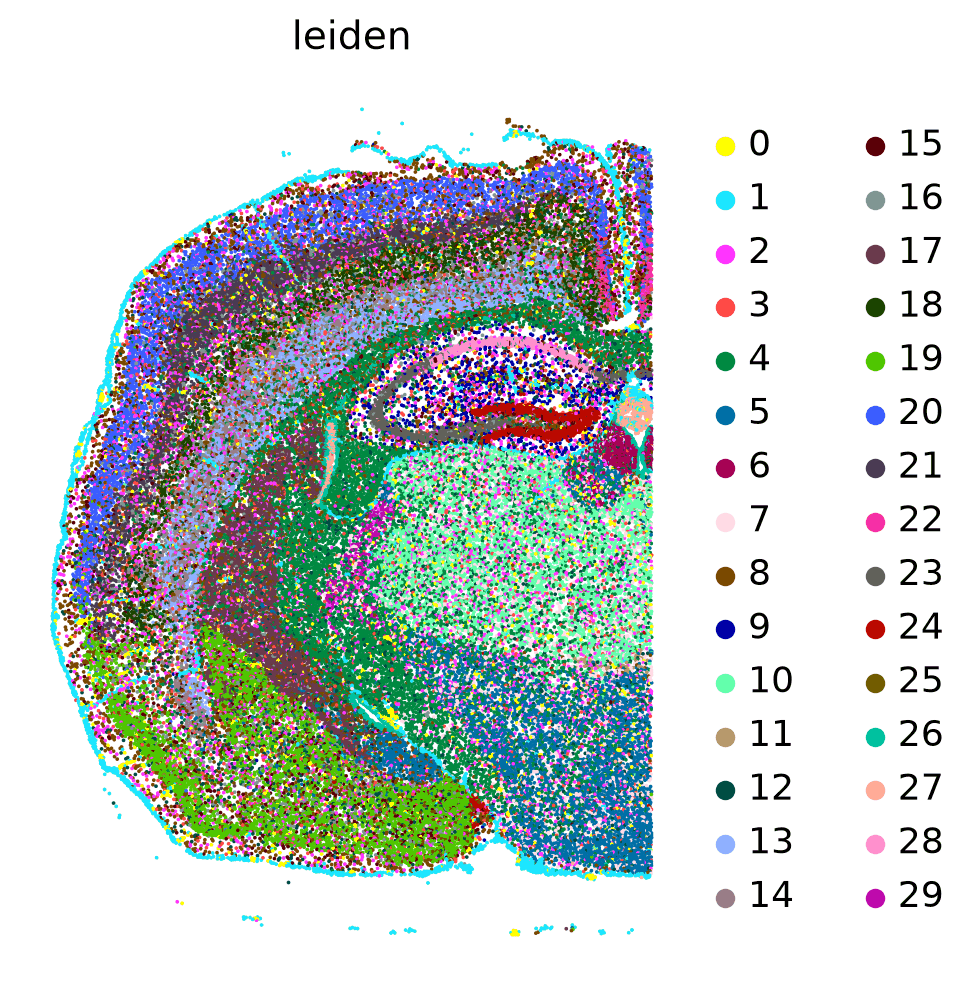

In [14]:
sc.pl.spatial(adata_den, color="leiden", spot_size=30, frameon=False)
plt.show()

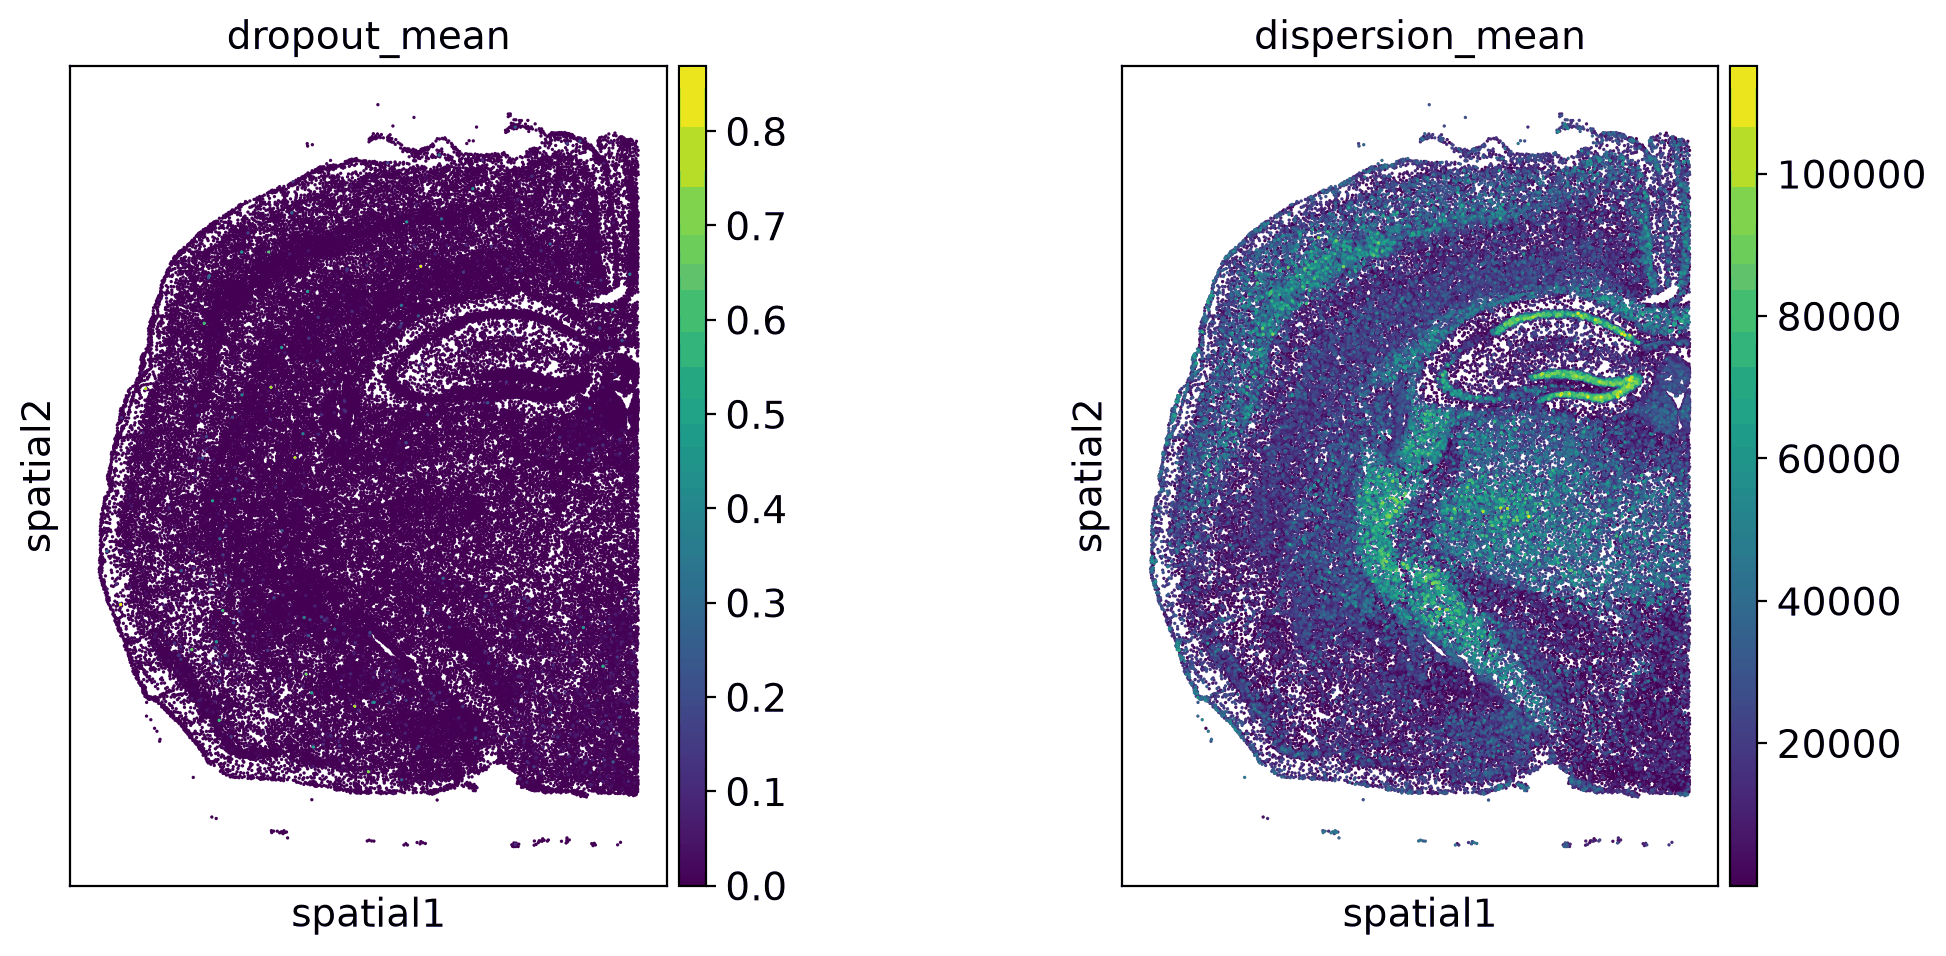

In [15]:
# The ZINB parameters are per-cell summaries of how noisy each cell is.
adata_den.obs["dropout_mean"] = adata_den.obsm["dropout"].mean(axis=-1)
adata_den.obs["dispersion_mean"] = adata_den.obsm["dispersion"].mean(axis=-1)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sc.pl.spatial(adata_den, color="dropout_mean",    spot_size=30, ax=axes[0], show=False)
sc.pl.spatial(adata_den, color="dispersion_mean", spot_size=30, ax=axes[1], show=False)
plt.tight_layout()
plt.show()

### 7d. Two genes at once

`Trem2` (microglia) and `Slc17a6` (thalamic excitatory neurons) mark different cell
types. In raw counts many cells carry some of both; after denoising almost every cell
sits on one axis or the other, so the two markers become close to mutually exclusive.

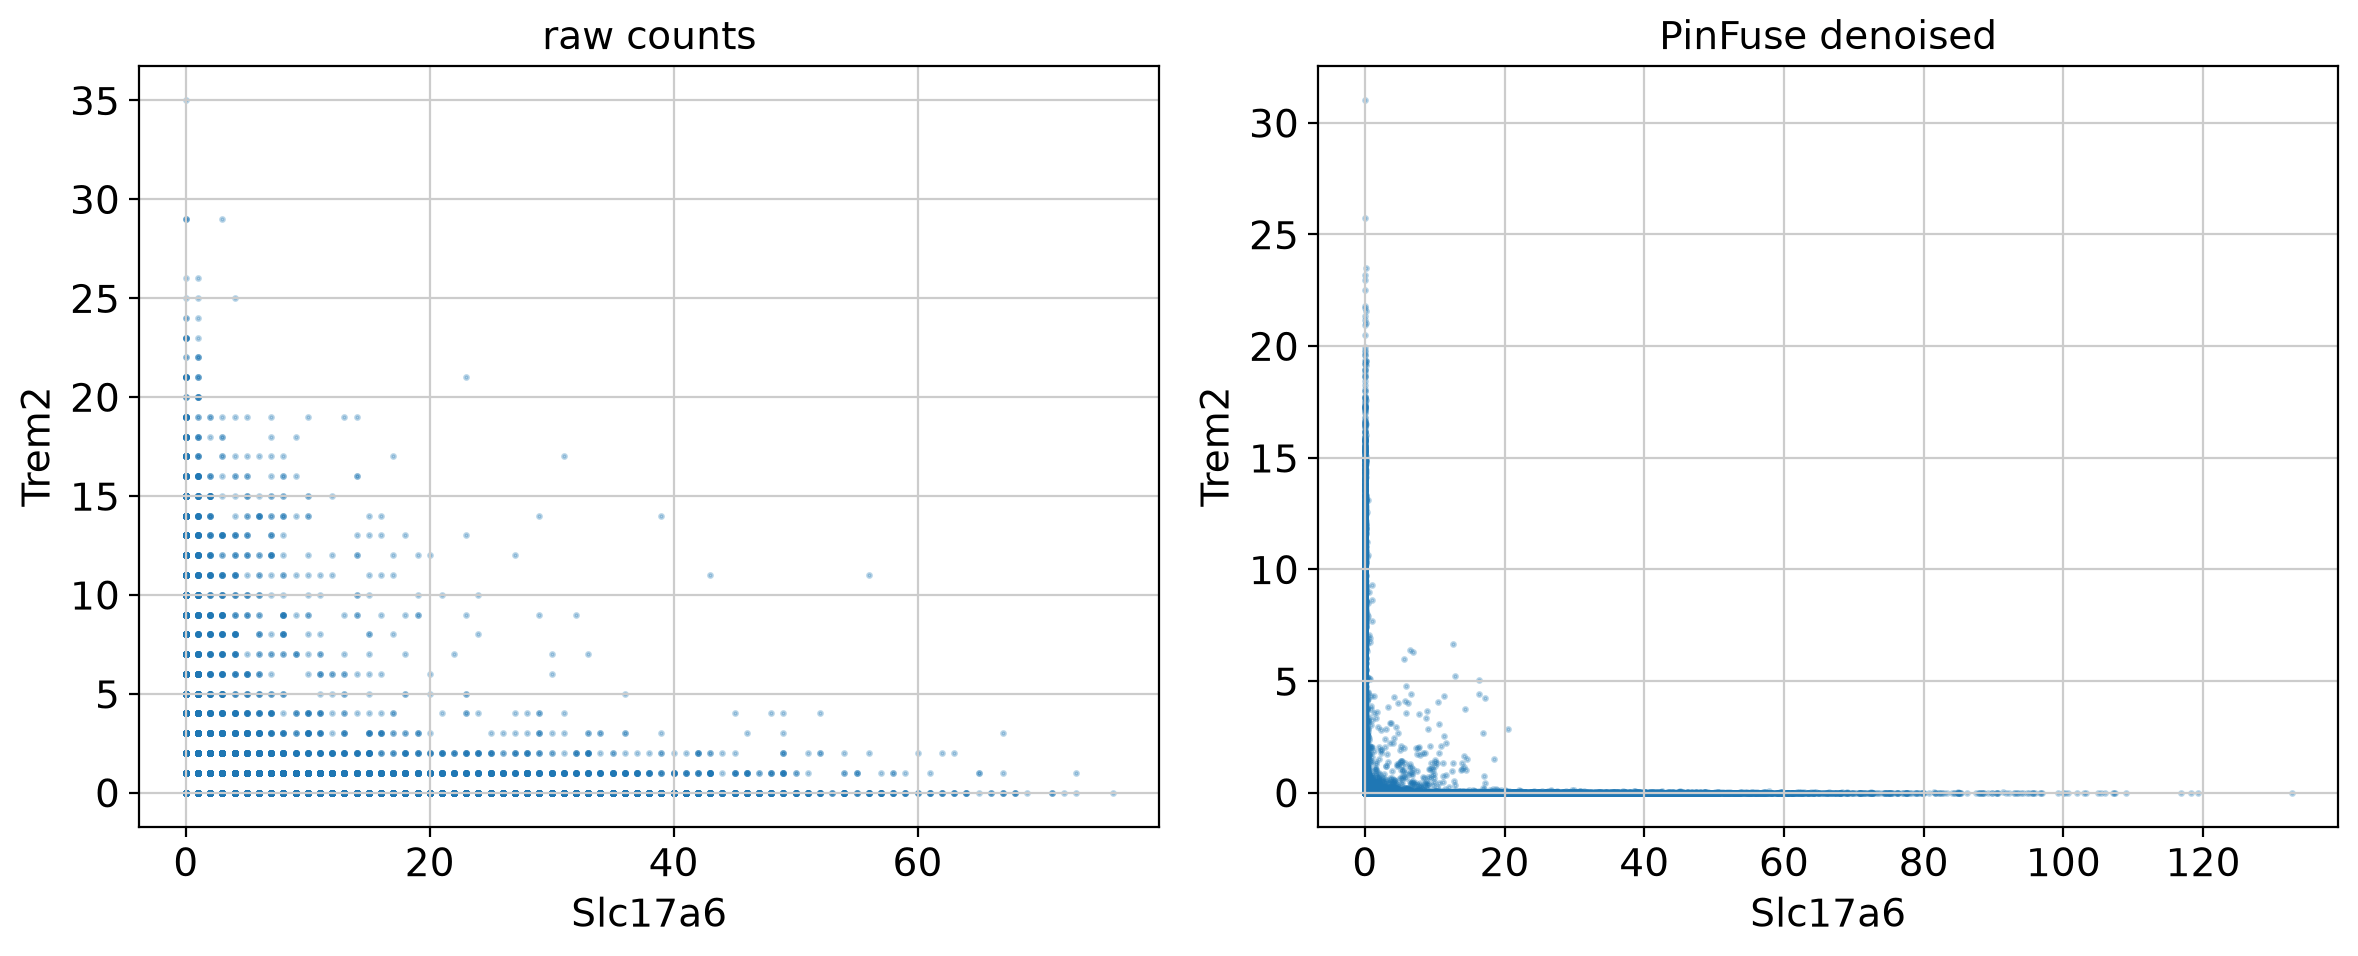

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, denoised in zip(axes, [False, True]):
    ax.scatter(gene_obs("Slc17a6", denoised), gene_obs("Trem2", denoised), s=2, alpha=0.3)
    ax.set_xlabel("Slc17a6")
    ax.set_ylabel("Trem2")
    ax.set_title("PinFuse denoised" if denoised else "raw counts")
plt.tight_layout()
plt.show()

## 8. Reusing the run

`train.run` wrote a checkpoint and the denoised AnnData. Both are read back with the
public helpers, so a later session (or a different crop of the same panel) can skip
training.

In [17]:
from dataio import load_data

# Reload the saved results without retraining.
data_reload = load_data(config, DST_DIR)
print("reloaded:", data_reload.adata.shape, "|", list(data_reload.adata.obsm)[:6], "...")

# Or predict with the checkpoint on new data: train.run(..., ckpt_dir=DST_DIR)
# The gene panel must match, in the same order.

reloaded: (66457, 248) | ['X_resolvi_transferred', 'X_spatial', 'X_umap_transferred', 'direction', 'direction_tol', 'dispersion'] ...
